In [1]:
# 1

import pandas as pd

df = pd.read_csv("zomato_ratings.csv")

Q1 = df["user_rating"].quantile(0.25)
Q3 = df["user_rating"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["user_rating"] < lower_limit) |
    (df["user_rating"] > upper_limit)
]

print("Outlier Indices:")
print(outliers.index.tolist())

print("\nOutlier Records:")
print(outliers)

Outlier Indices:
[13, 14]

Outlier Records:
    restaurant_id  restaurant_name  user_rating
13             14  Street Food Hub          2.1
14             15    Luxury Dining          9.8


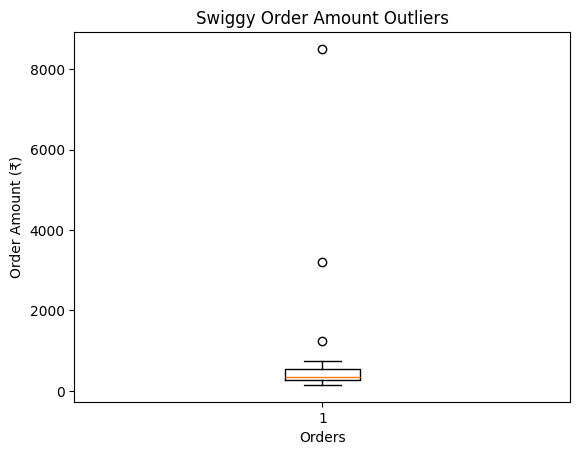

In [2]:
# 2

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("swiggy_orders.csv")

plt.boxplot(df["order_amount"].dropna())

plt.title("Swiggy Order Amount Outliers")
plt.xlabel("Orders")
plt.ylabel("Order Amount (₹)")

plt.show()

In [3]:
# 3

import pandas as pd

df = pd.DataFrame({
    "transaction_amount": [
        100, 200, 300, 400, 500,
        600, 700, 800, 900, 1000,
        1500, 2000, 5000, 10000, 50000
    ]
})

print("Original Statistics:")
print(df["transaction_amount"].describe())

lower_limit = df["transaction_amount"].quantile(0.05)
upper_limit = df["transaction_amount"].quantile(0.95)

df["transaction_amount"] = df["transaction_amount"].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("\nUpdated Transaction Amounts:")
print(df["transaction_amount"])

print("\nUpdated Statistics:")
print(df["transaction_amount"].describe())

Original Statistics:
count       15.000000
mean      4933.333333
std      12733.626274
min        100.000000
25%        450.000000
50%        800.000000
75%       1750.000000
max      50000.000000
Name: transaction_amount, dtype: float64

Updated Transaction Amounts:
0       170.0
1       200.0
2       300.0
3       400.0
4       500.0
5       600.0
6       700.0
7       800.0
8       900.0
9      1000.0
10     1500.0
11     2000.0
12     5000.0
13    10000.0
14    22000.0
Name: transaction_amount, dtype: float64

Updated Statistics:
count       15.000000
mean      3071.333333
std       5840.881620
min        170.000000
25%        450.000000
50%        800.000000
75%       1750.000000
max      22000.000000
Name: transaction_amount, dtype: float64


In [4]:
# 4

import pandas as pd

df = pd.DataFrame({
    "product_name": [
        "Laptop",
        "Mobile",
        "Headphones",
        "Keyboard",
        "Mouse"
    ],
    "price": [
        "₹55,999",
        "₹24,999",
        "₹1,299",
        "₹899",
        "₹499"
    ]
})

print("Original DataFrame:")
print(df)

df["price"] = df["price"].str.replace(
    r"[^\d.]",
    "",
    regex=True
)

df["price"] = df["price"].astype(float)

print("\nUpdated DataFrame:")
print(df)

print("\nPrice Data Type:")
print(df["price"].dtype)

Original DataFrame:
  product_name    price
0       Laptop  ₹55,999
1       Mobile  ₹24,999
2   Headphones   ₹1,299
3     Keyboard     ₹899
4        Mouse     ₹499

Updated DataFrame:
  product_name    price
0       Laptop  55999.0
1       Mobile  24999.0
2   Headphones   1299.0
3     Keyboard    899.0
4        Mouse    499.0

Price Data Type:
float64


In [5]:
# 5

import pandas as pd

df = pd.DataFrame({
    "username": [
        "Rahul",
        "Priya",
        "Amit",
        "Neha",
        "Raj",
        "Karan",
        "Anjali",
        "Vishal"
    ],
    "is_premium": [
        True,
        "True",
        1,
        "yes",
        False,
        "no",
        0,
        "premium"
    ]
})

print("Original DataFrame:")
print(df)

df["is_premium"] = df["is_premium"].apply(
    lambda x: str(x).strip().lower() in ["true", "1", "yes"]
)

print("\nUpdated DataFrame:")
print(df)

print("\nData Type:")
print(df["is_premium"].dtype)

Original DataFrame:
  username is_premium
0    Rahul       True
1    Priya       True
2     Amit          1
3     Neha        yes
4      Raj      False
5    Karan         no
6   Anjali          0
7   Vishal    premium

Updated DataFrame:
  username  is_premium
0    Rahul        True
1    Priya        True
2     Amit        True
3     Neha        True
4      Raj       False
5    Karan       False
6   Anjali       False
7   Vishal       False

Data Type:
bool
